# 📊 Superstore Sales Analysis & Business Intelligence
## 📌 Project Overview
This project presents a comprehensive Exploratory Data Analysis (EDA) of the retail Superstore sales dataset (2015–2018). The primary goal is to audit data integrity, calculate key financial metrics, understand consumer behavior across various market segments, and identify macro trends to inform business decision-making.

## 🎯 Objectives
- **Data Cleaning & Auditing:** Inspect missing values, examine duplicated rows, and parse date fields into structured datetime formats.

- **Financial Metric Aggregation:** Accurately evaluate Total Revenue, Order Counts, and the true Average Order Value (AOV) at the order level.

- **Product & Category Performance:** Determine top revenue-generating inventory items and sales distribution across categories.

- **Time-Series Breakdown:** Analyze monthly and annual seasonality patterns across multiple operating years.

- **Data Visualization:** Create structured reporting dashboards and comparative visualizations using Matplotlib.

## 🛠️ Tech Stack
- **Language:** Python
- **Libraries:** Pandas, NumPy, Matplotlib
- **Environment:** Jupyter Notebook
## 📂 Dataset Information
- **Total Records:** 9,800 order line items
- **Attributes:** Order ID, Dates, Shipping Mode, Customer Demographics, Product Hierarchy, Sales

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("Superstore Sales Dataset.csv")
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9795,9796,CA-2017-125920,21/05/2017,28/05/2017,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980
9796,9797,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680
9797,9798,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.1880
9798,9799,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10000912,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.3760


In [14]:
df.shape

(9800, 18)

In [15]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [16]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
dtype: object

In [17]:
df.isna().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

#### Fisrt of all delete unnecessary columns

In [18]:
df1 = df.drop(['Row ID','Customer Name','Postal Code','Product ID','Country','City'] , axis="columns")
df1

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,State,Region,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Corporate,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Consumer,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Consumer,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
...,...,...,...,...,...,...,...,...,...,...,...,...
9795,CA-2017-125920,21/05/2017,28/05/2017,Standard Class,SH-19975,Corporate,Illinois,Central,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980
9796,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Corporate,Ohio,East,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680
9797,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,GE 30524EE4,235.1880
9798,CA-2016-128608,12/01/2016,17/01/2016,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.3760


In [19]:
df1.isna().sum()

Order ID        0
Order Date      0
Ship Date       0
Ship Mode       0
Customer ID     0
Segment         0
State           0
Region          0
Category        0
Sub-Category    0
Product Name    0
Sales           0
dtype: int64

In [20]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order ID      9800 non-null   object 
 1   Order Date    9800 non-null   object 
 2   Ship Date     9800 non-null   object 
 3   Ship Mode     9800 non-null   object 
 4   Customer ID   9800 non-null   object 
 5   Segment       9800 non-null   object 
 6   State         9800 non-null   object 
 7   Region        9800 non-null   object 
 8   Category      9800 non-null   object 
 9   Sub-Category  9800 non-null   object 
 10  Product Name  9800 non-null   object 
 11  Sales         9800 non-null   float64
dtypes: float64(1), object(11)
memory usage: 918.9+ KB


In [21]:
df1.duplicated().sum()

np.int64(1)

In [22]:
df1['Customer ID'].nunique()

793

In [23]:
df1['Segment'].nunique()

3

In [24]:
df1['Segment'].unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

In [25]:
df1['Region'].unique()

array(['South', 'West', 'Central', 'East'], dtype=object)

In [26]:
df1['State'].nunique()

49

In [27]:
df1['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [28]:
df1['Sub-Category'].unique()

array(['Bookcases', 'Chairs', 'Labels', 'Tables', 'Storage',
       'Furnishings', 'Art', 'Phones', 'Binders', 'Appliances', 'Paper',
       'Accessories', 'Envelopes', 'Fasteners', 'Supplies', 'Machines',
       'Copiers'], dtype=object)

In [29]:
df1['Ship Mode'].unique()

array(['Second Class', 'Standard Class', 'First Class', 'Same Day'],
      dtype=object)

In [30]:
df1['Order Date'] = pd.to_datetime(df1['Order Date'], format= '%d/%m/%Y')
df1['Ship Date'] = pd.to_datetime(df1['Ship Date'], format= '%d/%m/%Y')

In [31]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      9800 non-null   object        
 1   Order Date    9800 non-null   datetime64[ns]
 2   Ship Date     9800 non-null   datetime64[ns]
 3   Ship Mode     9800 non-null   object        
 4   Customer ID   9800 non-null   object        
 5   Segment       9800 non-null   object        
 6   State         9800 non-null   object        
 7   Region        9800 non-null   object        
 8   Category      9800 non-null   object        
 9   Sub-Category  9800 non-null   object        
 10  Product Name  9800 non-null   object        
 11  Sales         9800 non-null   float64       
dtypes: datetime64[ns](2), float64(1), object(9)
memory usage: 918.9+ KB


In [32]:
df1

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,State,Region,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Corporate,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Consumer,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Consumer,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
...,...,...,...,...,...,...,...,...,...,...,...,...
9795,CA-2017-125920,2017-05-21,2017-05-28,Standard Class,SH-19975,Corporate,Illinois,Central,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980
9796,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680
9797,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,GE 30524EE4,235.1880
9798,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.3760


In [33]:
df1['Sales'] = df1['Sales'].round(3)
df1

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,State,Region,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.960
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Consumer,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Corporate,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Consumer,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.578
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Consumer,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368
...,...,...,...,...,...,...,...,...,...,...,...,...
9795,CA-2017-125920,2017-05-21,2017-05-28,Standard Class,SH-19975,Corporate,Illinois,Central,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.798
9796,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.368
9797,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,GE 30524EE4,235.188
9798,CA-2016-128608,2016-01-12,2016-01-17,Standard Class,CS-12490,Corporate,Ohio,East,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.376


In [34]:
total_sales = df1['Sales'].sum()
print(total_sales)

2261536.784


## AOV(Average Order Value) = Total Revenue/Unique Orders

In [35]:
aov = total_sales/df1['Order ID'].nunique()
print(f'total sales are ${total_sales:,.2f}')
print(df1['Order ID'].nunique())
print(f'AOV is ${aov:,.2f}')

total sales are $2,261,536.78
4922
AOV is $459.48


In [36]:
df1.columns.tolist()

['Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Segment',
 'State',
 'Region',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales']

In [37]:
df2 = df1.sort_values(by= 'Order Date').reset_index()
df2

,index,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,State,Region,Category,Sub-Category,Product Name,Sales
0,7980,CA-2015-103800,2015-01-03,2015-01-07,Standard Class,DP-13000,Consumer,Texas,Central,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448
1,741,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540
2,740,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736
3,739,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Labels,Avery 508,11.784
4,1759,CA-2015-141817,2015-01-05,2015-01-12,Standard Class,MB-18085,Consumer,Pennsylvania,East,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9795,1297,CA-2018-115427,2018-12-30,2019-01-03,Standard Class,EB-13975,Corporate,California,West,Office Supplies,Binders,GBC Binding covers,20.720
9796,906,CA-2018-143259,2018-12-30,2019-01-03,Standard Class,PO-18865,Consumer,New York,East,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Fully Ass...",323.136
9797,645,CA-2018-126221,2018-12-30,2019-01-05,Standard Class,CC-12430,Home Office,Indiana,Central,Office Supplies,Appliances,Eureka The Boss Plus 12-Amp Hard Box Upright V...,209.300
9798,908,CA-2018-143259,2018-12-30,2019-01-03,Standard Class,PO-18865,Consumer,New York,East,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776


In [38]:
df2['Year'] = df2['Order Date'].dt.year

In [39]:
df2['Month'] = df2['Order Date'].dt.month

In [40]:
df2['Year_Month'] = df2['Order Date'].dt.to_period('M')

In [41]:
#df2 = df2.drop(['index'] , axis='columns')
df2

,index,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,State,Region,Category,Sub-Category,Product Name,Sales,Year,Month,Year_Month
0,7980,CA-2015-103800,2015-01-03,2015-01-07,Standard Class,DP-13000,Consumer,Texas,Central,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2015,1,2015-01
1,741,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2015,1,2015-01
2,740,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,2015,1,2015-01
3,739,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Home Office,Illinois,Central,Office Supplies,Labels,Avery 508,11.784,2015,1,2015-01
4,1759,CA-2015-141817,2015-01-05,2015-01-12,Standard Class,MB-18085,Consumer,Pennsylvania,East,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,2015,1,2015-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9795,1297,CA-2018-115427,2018-12-30,2019-01-03,Standard Class,EB-13975,Corporate,California,West,Office Supplies,Binders,GBC Binding covers,20.720,2018,12,2018-12
9796,906,CA-2018-143259,2018-12-30,2019-01-03,Standard Class,PO-18865,Consumer,New York,East,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Fully Ass...",323.136,2018,12,2018-12
9797,645,CA-2018-126221,2018-12-30,2019-01-05,Standard Class,CC-12430,Home Office,Indiana,Central,Office Supplies,Appliances,Eureka The Boss Plus 12-Amp Hard Box Upright V...,209.300,2018,12,2018-12
9798,908,CA-2018-143259,2018-12-30,2019-01-03,Standard Class,PO-18865,Consumer,New York,East,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,2018,12,2018-12


In [42]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   index         9800 non-null   int64         
 1   Order ID      9800 non-null   object        
 2   Order Date    9800 non-null   datetime64[ns]
 3   Ship Date     9800 non-null   datetime64[ns]
 4   Ship Mode     9800 non-null   object        
 5   Customer ID   9800 non-null   object        
 6   Segment       9800 non-null   object        
 7   State         9800 non-null   object        
 8   Region        9800 non-null   object        
 9   Category      9800 non-null   object        
 10  Sub-Category  9800 non-null   object        
 11  Product Name  9800 non-null   object        
 12  Sales         9800 non-null   float64       
 13  Year          9800 non-null   int32         
 14  Month         9800 non-null   int32         
 15  Year_Month    9800 non-null   period[M

In [43]:
Yearly_sales = (df2.groupby('Year')["Sales"].sum().reset_index().sort_values(by='Year'))

In [44]:
Yearly_sales[ 'Sales_formatted'] = Yearly_sales['Sales'].apply(lambda x: f'${x:,.2f}')

In [45]:
print(Yearly_sales[['Year' , 'Sales_formatted']])

   Year Sales_formatted
0  2015     $479,856.21
1  2016     $459,436.01
2  2017     $600,192.55
3  2018     $722,052.02


### TOP 15 product sales

In [46]:
p_sales = (df2.groupby('Product Name')["Sales"].sum().reset_index().sort_values(by='Sales' , ascending=False))
p_sales.head(15)

,Product Name,Sales
404,Canon imageCLASS 2200 Advanced Copier,61599.824
649,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480
785,HON 5400 Series Task Chairs for Big and Tall,21870.576
685,GBC DocuBind TL300 Electric Binding System,19823.479
687,GBC Ibimaster 500 Manual ProClick Binding System,19024.500
804,Hewlett Packard LaserJet 3310 Copier,18839.686
786,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
682,GBC DocuBind P400 Electric Binding System,17965.068
812,High Speed Automatic Electric Letter Opener,17030.312


In [47]:
df2.groupby('Product Name')["Sales"].sum().reset_index().sort_values(by='Sales' , ascending=True).tail(15)

,Product Name,Sales
19,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890
1350,"Riverside Palais Royal Lawyers Bookcase, Royal...",15610.966
894,Ibico EPK-21 Electric Binding System,15875.916
1042,Martin Yale Chadless Opener Electric Letter Op...,16656.200
984,Lexmark MX611dhe Monochrome Laser Printer,16829.901
812,High Speed Automatic Electric Letter Opener,17030.312
682,GBC DocuBind P400 Electric Binding System,17965.068
786,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
804,Hewlett Packard LaserJet 3310 Copier,18839.686
687,GBC Ibimaster 500 Manual ProClick Binding System,19024.500


In [48]:
product = df2['Category']

In [49]:
Yearly_breakdown = df2.groupby(['Year' ,product])["Sales"].sum().reset_index().sort_values(by=['Year','Sales'],)

In [50]:
Yearly_breakdown

,Year,Category,Sales
1,2015,Office Supplies,149512.820
0,2015,Furniture,156477.880
2,2015,Technology,173865.507
4,2016,Office Supplies,133124.407
5,2016,Technology,162257.731
3,2016,Furniture,164053.869
7,2017,Office Supplies,182417.566
6,2017,Furniture,195813.041
8,2017,Technology,221961.944
9,2018,Furniture,212313.787


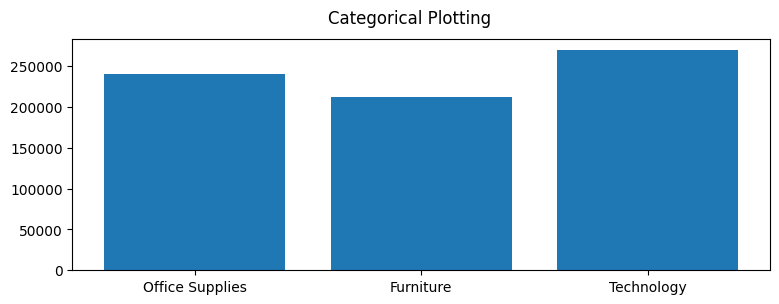

In [54]:
plt.figure(figsize=(9, 3))
#plt.subplot(131)
plt.bar(Yearly_breakdown['Category'], Yearly_breakdown['Sales'])
plt.suptitle('Categorical Plotting')
plt.show()

In [51]:
pivot_table = df2.pivot_table(
    index= product,
    columns='Year',
    values= 'Sales',
    aggfunc='sum',
    fill_value= 0)

In [52]:
pivot_table.map('${:,.2f}'.format)

Year,2015,2016,2017,2018
Category,,,,
Furniture,"$156,477.88","$164,053.87","$195,813.04","$212,313.79"
Office Supplies,"$149,512.82","$133,124.41","$182,417.57","$240,367.54"
Technology,"$173,865.51","$162,257.73","$221,961.94","$269,370.69"


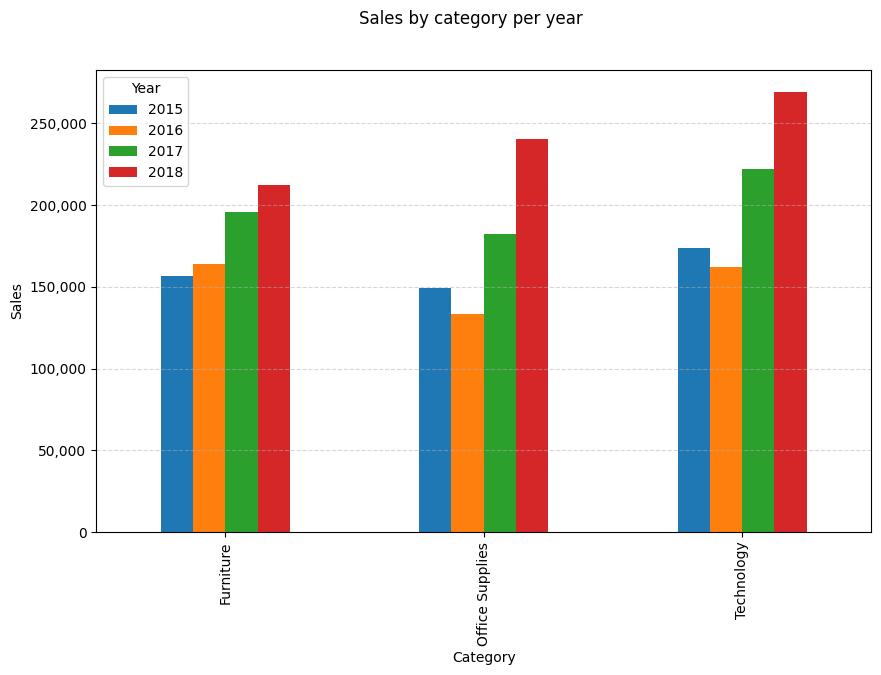

In [70]:
ax = pivot_table.plot(kind='bar',figsize=(10, 6))
plt.xlabel('Category')
plt.ylabel('Sales')
plt.suptitle('Sales by category per year')
ax.yaxis.set_major_formatter('{x:,.0f}')
plt.grid(axis='y' , linestyle='--',alpha=0.5)
plt.show()

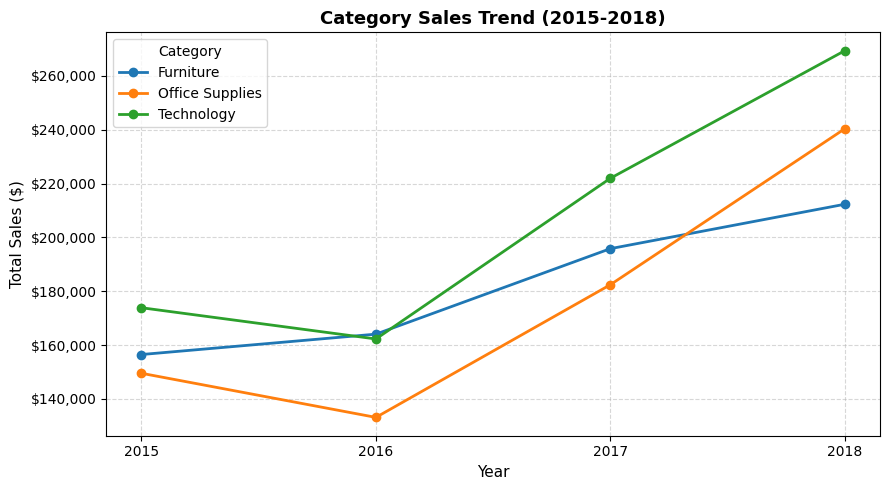

In [77]:
ax = pivot_table.T.plot(kind='line', marker='o', linewidth=2, figsize=(9, 5))
plt.title('Category Sales Trend (2015-2018)', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.xticks(pivot_table.columns)  # نمایش دقیق هر ۴ سال
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Category')
plt.tight_layout()
plt.show()

In [79]:
pivot_table2 = df2.pivot_table(
    columns='Year',
    values= 'Sales',
    aggfunc='sum',
    fill_value= 0)
pivot_table2.map('${:,.2f}'.format)

Year,2015,2016,2017,2018
Sales,"$479,856.21","$459,436.01","$600,192.55","$722,052.02"


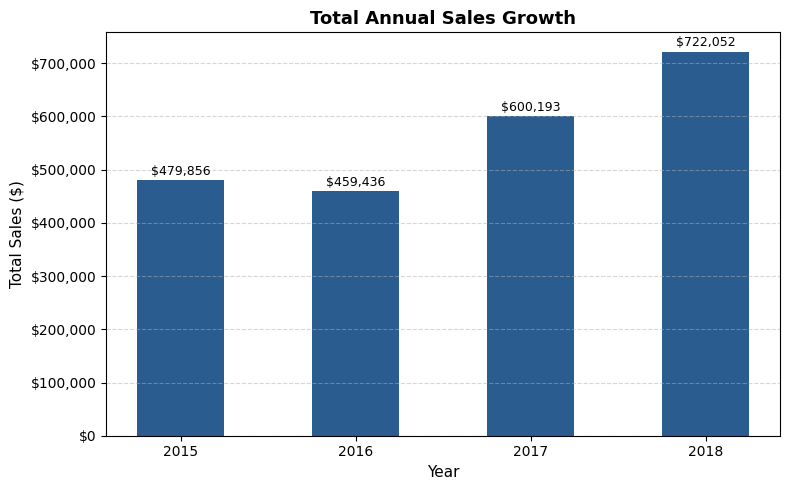

In [80]:
yearly_total = pivot_table2.loc['Sales']
plt.figure(figsize=(8, 5))
bars = plt.bar(yearly_total.index.astype(str), yearly_total.values, color='#2b5c8f', width=0.5)
plt.title('Total Annual Sales Growth', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10000, f'${yval:,.0f}', ha='center', fontsize=9)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

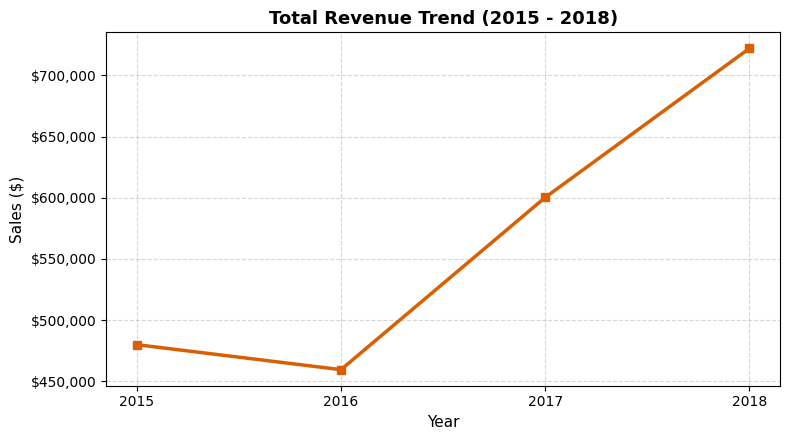

In [82]:
yearly_total = pivot_table2.loc['Sales']

plt.figure(figsize=(8, 4.5))
plt.plot(yearly_total.index.astype(str), yearly_total.values, marker='s', markersize=6, color='#d95f02', linewidth=2.5)

plt.title('Total Revenue Trend (2015 - 2018)', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Sales ($)', fontsize=11)

plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

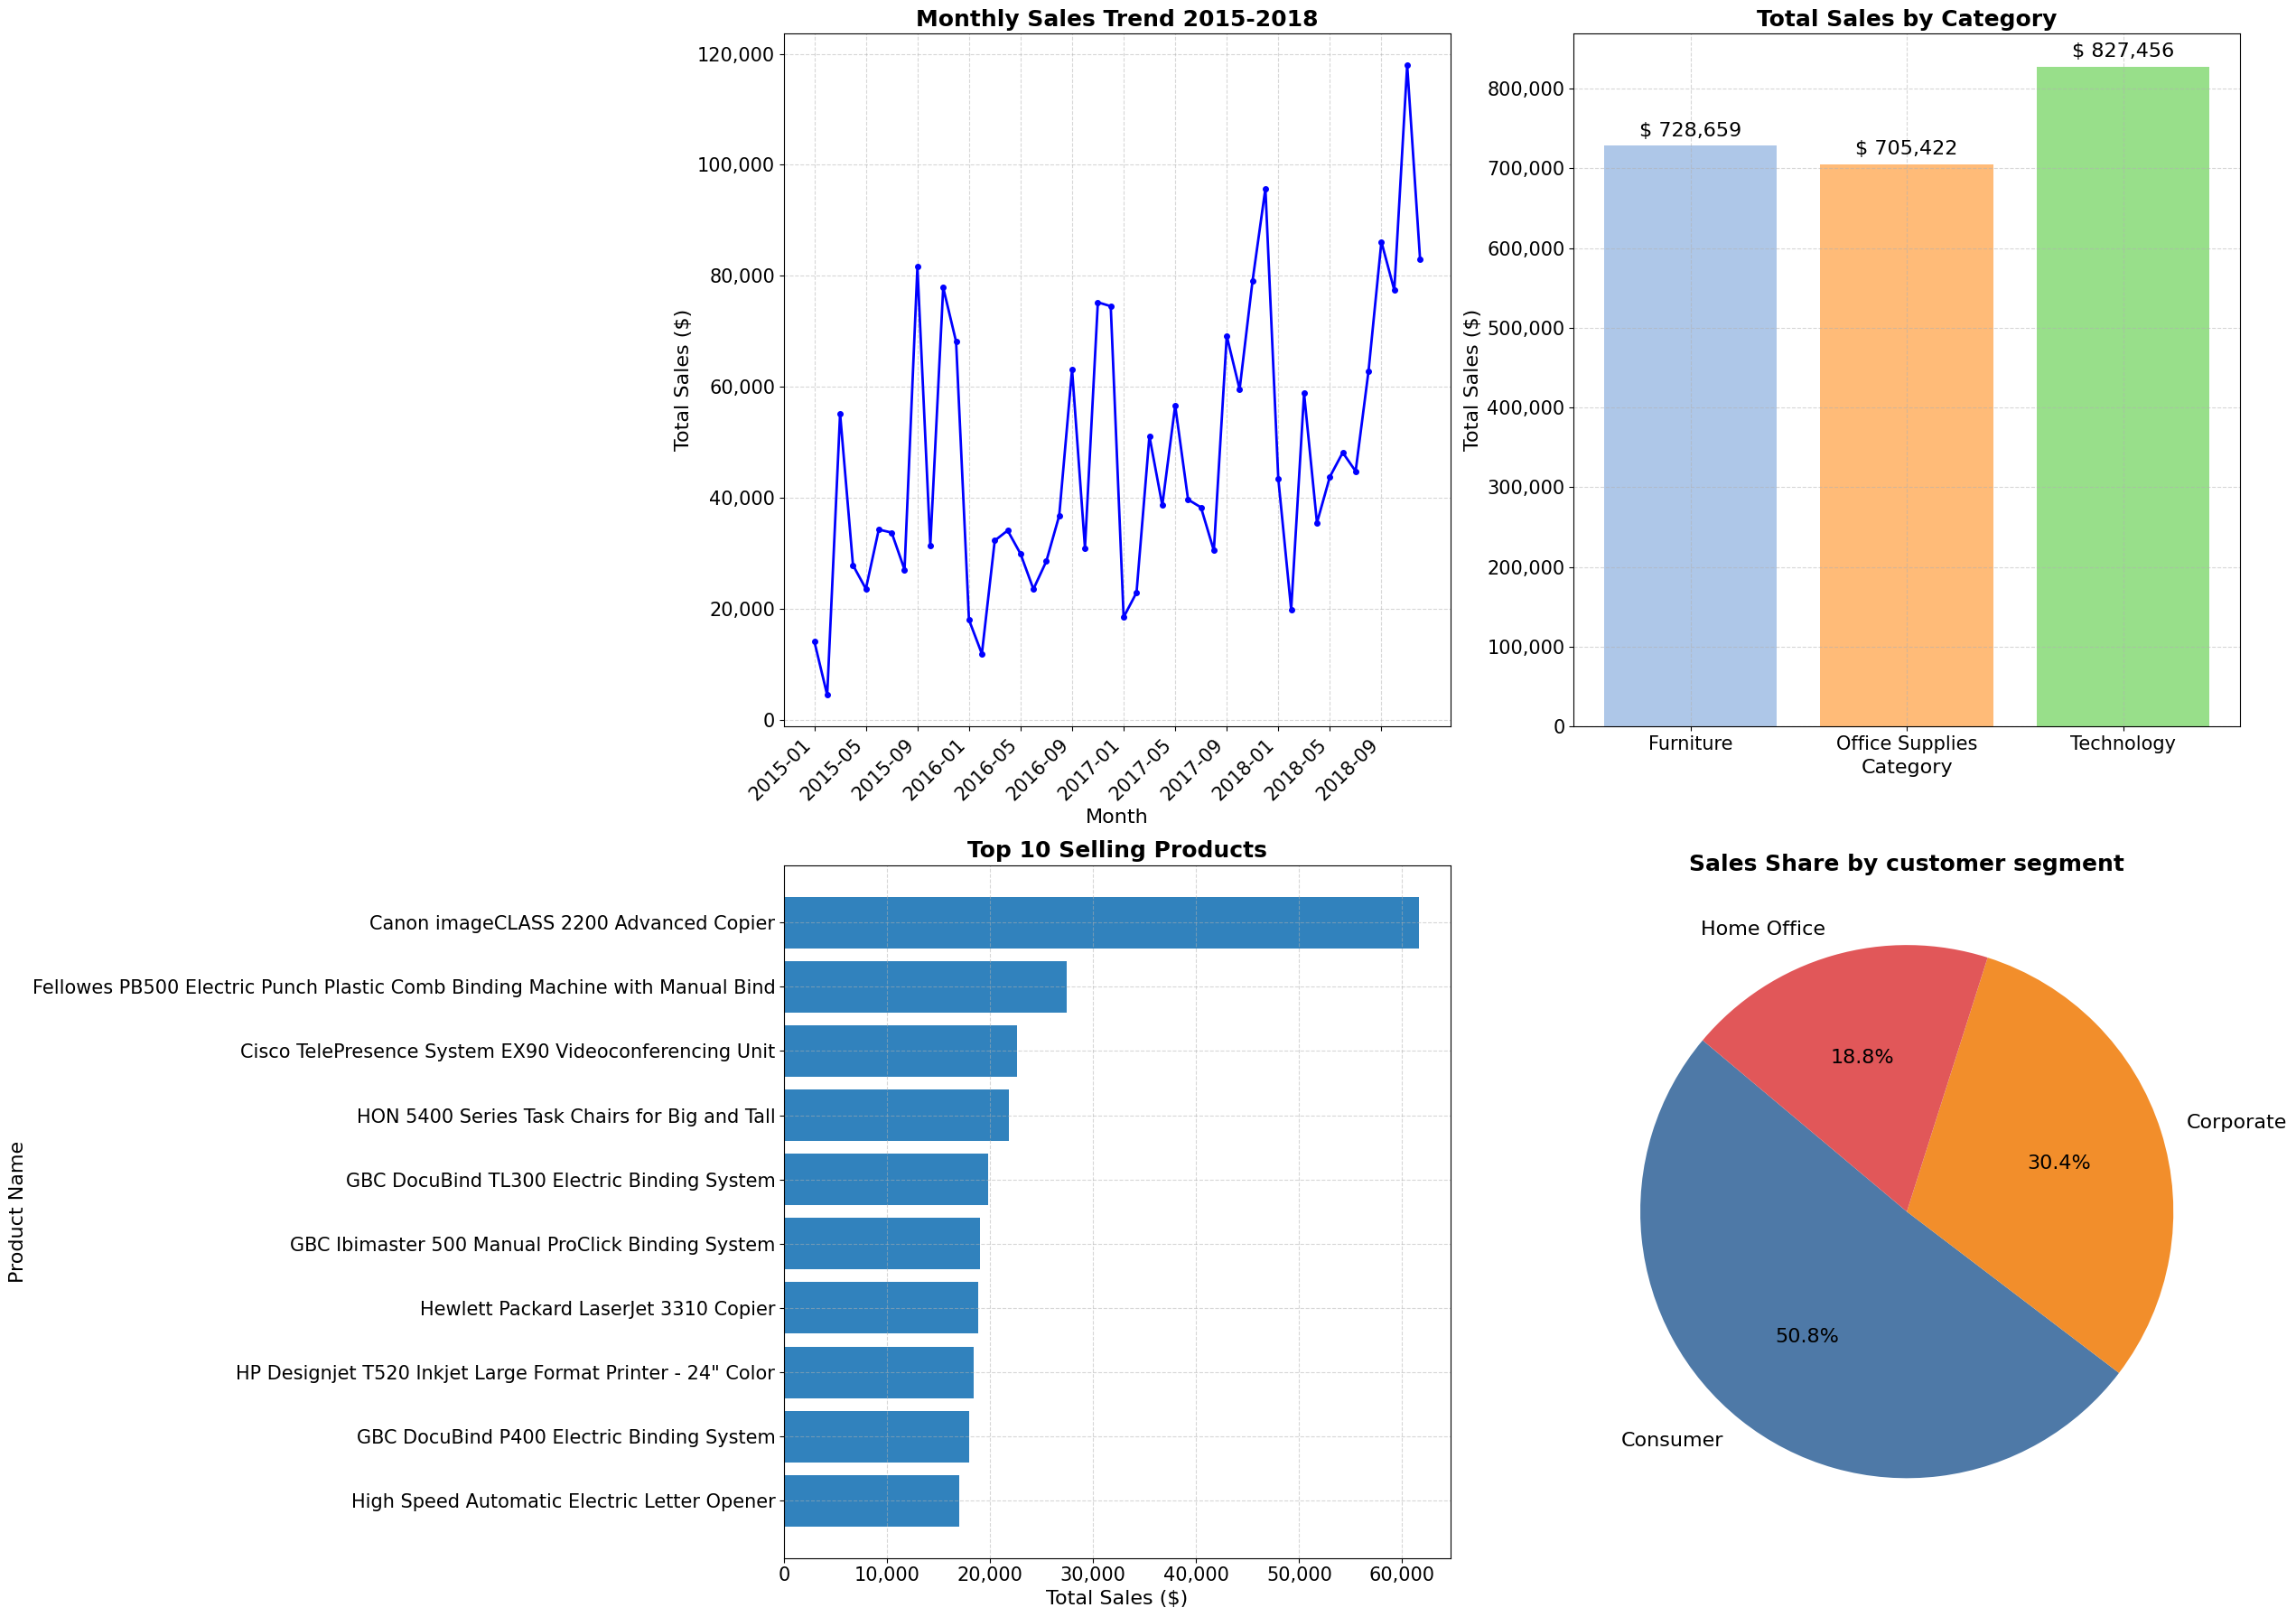

In [218]:
fig, axes = plt.subplots(nrows=2 , ncols=2,figsize=(25, 18))
#Monthly sales 2015-2018

#sub plot 1
ax1= axes[0,0]
#filter
mask_years = (df2["Year"] >= 2015) & (df2["Year"] <=2018)
monthly_sales = df2[mask_years].groupby('Year_Month')['Sales'].sum().reset_index().sort_values('Year_Month')
#Change Year_Month to str for X axis
x_labels = monthly_sales['Year_Month'].astype(str)#dt.strftime('%y-%m')
ax1.plot(x_labels, monthly_sales['Sales'], marker='o' , markersize=4, color = "b", linewidth=2)
ax1.set_title("Monthly Sales Trend 2015-2018", fontweight='bold', fontsize = 18)
ax1.set_xlabel("Month", fontsize = 16)
ax1.set_ylabel("Total Sales ($)", fontsize = 16)
ax1.yaxis.set_major_formatter('{x:,.0f}')
ax1.set_xticks(range(0, len(x_labels),4))
ax1.set_xticklabels(x_labels[::4], rotation=45, ha='right')
ax1.grid(True , linestyle='--',alpha=0.5)
ax1.tick_params(axis='both' , labelsize = 15)

#sub plot 2
ax2= axes[0,1]
Category_Sales = df2.groupby('Category')['Sales'].sum()
categories = Category_Sales.index
sales_val = Category_Sales.values
bars = ax2.bar(categories,sales_val , color=['#aec7e8' , '#ffbb78', '#98df8a'])
ax2.set_title("Total Sales by Category", fontweight='bold', fontsize = 18)
ax2.set_xlabel("Category", fontsize = 16)
ax2.set_ylabel("Total Sales ($)", fontsize = 16)
ax2.yaxis.set_major_formatter('{x:,.0f}')
ax2.grid(True , linestyle='--',alpha=0.5)

for bar in bars:
    yval=bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() /2 ,
        yval + (yval*0.01),
        f'${yval: ,.0f}',
        ha='center',
        va = 'bottom' ,
        fontsize = 16
    )
ax2.tick_params(axis='both' , labelsize = 15)
#sub plot 3
ax3 = axes[1,0]
topsales = df2.groupby('Product Name')["Sales"].sum().sort_values(ascending=True).tail(10)
ax3.barh(topsales.index , topsales.values , color = "#3182bd")
ax3.set_title("Top 10 Selling Products", fontweight='bold', fontsize = 18)
ax3.set_xlabel("Total Sales ($)", fontsize = 16)
ax3.set_ylabel("Product Name", fontsize = 16)
ax3.xaxis.set_major_formatter('{x:,.0f}')
ax3.grid(True , linestyle='--',alpha=0.5)
ax3.tick_params(axis='both' , labelsize = 15)
#sub plot 4
ax4 = axes[1,1]
segment_sales = df2.groupby('Segment')["Sales"].sum()
colors =['#4e79a7' , '#f28e2b', '#e15759']
ax4.pie(segment_sales ,
       labels=segment_sales.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        textprops = {'fontsize':16}
        
       )
#plt.setp(autotexts, size=15 , weight='bold')
ax4.set_title("Sales Share by customer segment", fontsize = 18,fontweight='bold')
ax4.tick_params(axis='both' , labelsize = 15)
#ax4.set_xlabel("Total Sales ($)")
#ax4.set_ylabel("Product Name")
#ax4.xaxis.set_major_formatter('{x:,.0f}')
plt.tight_layout()
plt.show()

# Executive Summary & Business Insights
### 1. Dataset Overview
- **Scope:** 9,800 order line items covering transactions from January 2015 to December 2018 across the US market.
- **Data Integrity:** Missing values were limited to 11 records in 'Postal Code' (non-critical). Dates were parsed to datetime ('DD/MM/YYYY') and chronologically sorted.

### 2. Key Performance Indicators (KPIs)
**Total Revenue:** $2,261,536.78

**Total Unique Orders:** 4,922 orders

**Average Order Value (AOV):** $459.48 per order

### 3. Business Insights
1. **Consistent Revenue Growth:** Annual sales grew from $479.8K (2015) to $722K (2018), marking an overall growth of ~50.4%. While 2016 experienced a minor contraction (-4.2%), the business rebounded strongly in 2017 (+30.6%) and maintained momentum in 2018.


2. **Technology Dominance:** The Technology category is the primary revenue driver, generating the highest total sales across all 4 years ($269.3K in 2018 alone), followed by 'Office Supplies' and 'Furniture'.

3. **High Revenue Concentration (Pareto Principle):** A small fraction of products generates a disproportionate share of total revenue. Specifically, the top product (Canon imageCLASS 2200 Advanced Copier) generated $61,599.82, which is more than double the second-highest product.

4. **Multi-Item Order Behavior:** With 9,800 line items across 4,922 distinct orders, each order contains an average of ~2 line items. This confirms the critical distinction between row-level mean and true order-level AOV ($459.48).

5. **Operational Seasonality:** Monthly transaction volumes show noticeable cyclical peaks toward Q4 (holiday shopping and year-end enterprise procurement), which should guide inventory stocking.